# **Membuat Model NLP dengan TensorFlow**
**Nama : Doni Firmansyah**

# **1. Collecting Dataset**
Dataset yang digunakan adalah movie genre dari :
https://www.kaggle.com/datasets/lokkagle/movie-genre-data

In [ ]:
import pandas as pd
# membaca dataset dari file csv
dataFrame = pd.read_csv('kaggle_movie_train.csv')
# menampilkan informasi dataset
print(dataFrame.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22579 entries, 0 to 22578
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      22579 non-null  int64 
 1   text    22579 non-null  object
 2   genre   22579 non-null  object
dtypes: int64(1), object(2)
memory usage: 529.3+ KB
None


# **2. Cleaning Dataset**
Menghapus dataset kosong dan yang tidak diperlukan

In [ ]:
# menghapus dataset kosong, jika ada.
dataFrame.dropna(axis=0,inplace=True)
print(dataFrame.info())
# menghapus kolom yang tidak dibutuhkan (id)
dataFrame.drop(columns= 'id', inplace= True)
print(dataFrame.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22579 entries, 0 to 22578
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      22579 non-null  int64 
 1   text    22579 non-null  object
 2   genre   22579 non-null  object
dtypes: int64(1), object(2)
memory usage: 529.3+ KB
None
                                                text     genre
0  eady dead, maybe even wishing he was. INT. 2ND...  thriller
1  t, summa cum laude and all. And I'm about to l...    comedy
2   up Come, I have a surprise.... She takes him ...     drama
3  ded by the two detectives. INT. JEFF'S APARTME...  thriller
4  nd dismounts, just as the other children reach...     drama


# **3. Pre-Processing Dataset**

## **One Hot Encoding**

In [ ]:
# one hot encoding
dataFrameGenre = pd.get_dummies(dataFrame["genre"])
# gabungkan dataframe
dataFrame = pd.concat([dataFrame, dataFrameGenre], axis=1)
# menghapus kolom yang tidak dibutuhkan (genre)
dataFrame.drop(columns='genre', inplace= True)
print(dataFrame.head())
print(dataFrame.info())

                                                text  action  adventure  \
0  eady dead, maybe even wishing he was. INT. 2ND...       0          0   
1  t, summa cum laude and all. And I'm about to l...       0          0   
2   up Come, I have a surprise.... She takes him ...       0          0   
3  ded by the two detectives. INT. JEFF'S APARTME...       0          0   
4  nd dismounts, just as the other children reach...       0          0   

   comedy  drama  horror  other  romance  sci-fi  thriller  
0       0      0       0      0        0       0         1  
1       1      0       0      0        0       0         0  
2       0      1       0      0        0       0         0  
3       0      0       0      0        0       0         1  
4       0      1       0      0        0       0         0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22579 entries, 0 to 22578
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ---

## **NLTK**

In [ ]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import re
from nltk.stem.snowball import SnowballStemmer

# download yang dibutuhkan library nltk
nltk.download('stopwords')
nltk.download('punkt')

# variable
baseWord = SnowballStemmer("english")
stopWordEng = stopwords.words('english')
initRow = 0
sumRow = dataFrame.shape[0]

# melakukan iterasi sejumlah baris dataset teks
for i in range(initRow, sumRow):
  # ambil value teks
  text = dataFrame['text'][i].lower()
  # menghilangkan karakter selain alphabet dalam teks
  text = re.sub(pattern= '[^A-Za-z]', repl= ' ', string= text)
  # pecah teks menjadi kata-kata
  words = text.split()
  # menghilangkan stopword (misal “the”, “a”, “an”, or “in” dalam bahasa inggris)
  words = [ word for word in words if word not in set(stopWordEng)]
  # menghilangkan imbuhan morfologis dari kata, sehingga hanya menyisakan kata dasar.
  words = [baseWord.stem(word)  for word in words]
  # merangkai setiap kata menjadi teks
  text = ' '.join(words)
  dataFrame.loc[i,"text"] = text

dataFrame.head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


,text,action,adventure,comedy,drama,horror,other,romance,sci-fi,thriller
0,eadi dead mayb even wish int nd floor hallway ...,0,0,0,0,0,0,0,0,1
1,summa cum laud launch brand new magazin call e...,0,0,1,0,0,0,0,0,0
2,come surpris take hand lead hallway salvator l...,0,0,0,1,0,0,0,0,0
3,ded two detect int jeff apart night medium sho...,0,0,0,0,0,0,0,0,1
4,nd dismount children reach throw arm embrac ch...,0,0,0,1,0,0,0,0,0


## **Split**

In [ ]:
from sklearn.model_selection import train_test_split

# ambil nama atribut
nameAttribute = dataFrame.columns[0]
# ubah atribut menjadi array
attribute = dataFrame[nameAttribute].values

# ambil nama label
nameLabel = dataFrame.columns[1:]
# ubah label menjadi array
label = dataFrame[nameLabel].values

# split dataset
attributeTrain, attributeTest, labelTrain, labelTest = train_test_split(attribute, label, test_size=0.2, random_state=1)
print(attribute.shape)
print(label.shape)
print(attributeTrain.shape)
print(labelTrain.shape)
print(attributeTest.shape)
print(labelTest.shape)

NameError: name 'dataFrame' is not defined

## **Tokenizer, Sequence, and Padding**

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

lenInputCol = 128
lenInputRow = 10000

# instasiasi
tokenizer = Tokenizer(num_words=lenInputRow, oov_token='-')
# fit teks ke tokenizer
tokenizer.fit_on_texts(attributeTrain)

# ambil sekuen text
sequencesAttributeTrain = tokenizer.texts_to_sequences(attributeTrain)
sequencesAttributeTest = tokenizer.texts_to_sequences(attributeTest)

# menyamaratakan kolom
paddedAttributeTrain = pad_sequences(sequencesAttributeTrain,padding='post',truncating='post',maxlen=lenInputCol)
paddedAttributeTest = pad_sequences(sequencesAttributeTest,padding='post',truncating='post',maxlen=lenInputCol)

## **Modelling**

In [ ]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=lenInputRow, output_dim=16,input_length=lenInputCol),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(9, activation='softmax')
])

model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_2 (Embedding)     (None, 128, 16)           160000    
                                                                 
 dropout_6 (Dropout)         (None, 128, 16)           0         
                                                                 
 lstm_2 (LSTM)               (None, 64)                20736     
                                                                 
 dropout_7 (Dropout)         (None, 64)                0         
                                                                 
 dense_6 (Dense)             (None, 128)               8320      
                                                                 
 dropout_8 (Dropout)         (None, 128)               0         
                                                                 
 dense_7 (Dense)             (None, 64)               

## **Callback**

In [ ]:
from tensorflow.keras.callbacks import Callback
class CustomCallback(Callback):

    def on_train_end(self, logs=None):
        # keys = list(logs.keys())
        # print(logs)
        print(
            f"Stop training; got accuracy: {logs.get('accuracy'):.2f}, val_accuracy: {logs.get('val_accuracy'):.2f}"
        )

    def on_epoch_end(self, epoch, logs=None):
        # print(logs)
        if logs.get("accuracy") > 0.90 and logs.get('val_accuracy') > 0.90:
            print(f"Training and Validation on epoch {epoch+1} get minimum accuracy (90%)")
            self.model.stop_training = True

    def on_train_batch_end(self, batch, logs=None):
        if logs.get("accuracy") > 0.90:
            print(
                "...Training: end of batch {}; got accuracy: {:.2f}".format(
                    batch+1, logs.get("accuracy")
                )
            )

    def on_test_batch_end(self, batch, logs=None):
        if logs.get("accuracy") > 0.90:
            print(
                "...Evaluating: end of batch {}; got accuracy: {:.2f}".format(
                    batch+1, logs.get("accuracy")
                )
            )

# **4. Fitting Dataset**

In [ ]:
num_epochs = 200
history = model.fit(paddedAttributeTrain, labelTrain, epochs=num_epochs, validation_data=(paddedAttributeTest, labelTest), verbose=2, callbacks=[CustomCallback()])

Streaming output truncated to the last 5000 lines.
...Training: end of batch 490; got accuracy: 0.96
...Training: end of batch 491; got accuracy: 0.96
...Training: end of batch 492; got accuracy: 0.96
...Training: end of batch 493; got accuracy: 0.96
...Training: end of batch 494; got accuracy: 0.96
...Training: end of batch 495; got accuracy: 0.96
...Training: end of batch 496; got accuracy: 0.96
...Training: end of batch 497; got accuracy: 0.96
...Training: end of batch 498; got accuracy: 0.96
...Training: end of batch 499; got accuracy: 0.96
...Training: end of batch 500; got accuracy: 0.96
...Training: end of batch 501; got accuracy: 0.96
...Training: end of batch 502; got accuracy: 0.96
...Training: end of batch 503; got accuracy: 0.96
...Training: end of batch 504; got accuracy: 0.96
...Training: end of batch 505; got accuracy: 0.96
...Training: end of batch 506; got accuracy: 0.96
...Training: end of batch 507; got accuracy: 0.96
...Training: end of batch 508; got accuracy: 0.96

# **5. Visualization**

## **Accuracy**

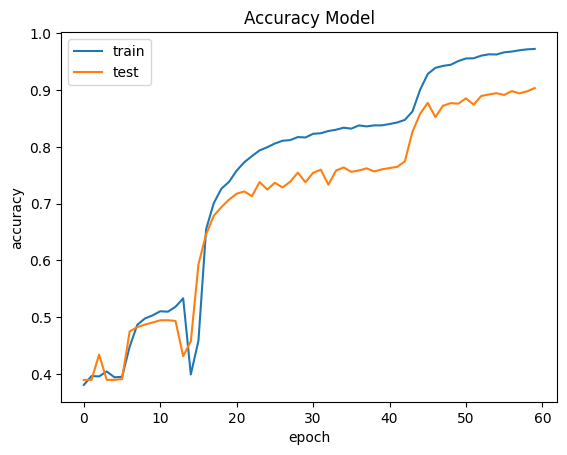

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Accuracy Model')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

## **Loss**

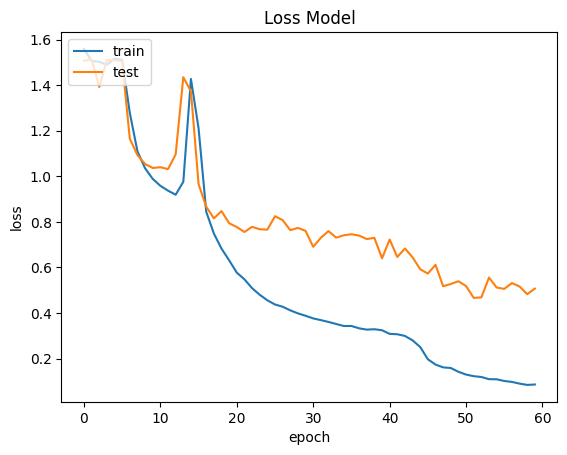

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Loss Model')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()